# Modelado paso a paso

Este notebook recorre el modelado completo, etapa por etapa, para poder ver qué
entra y qué sale en cada paso: desde la tabla de entrenamiento hasta el
artefacto que usa la app.

**No reimplementa nada.** Cada etapa llama a las mismas funciones de
`bolsalab/modeling/train.py` que usan los scripts, así que lo que se ve aquí es
exactamente lo que corre en el pipeline. Las reglas están en
`docs/protocolo-evaluacion.md`.

| Etapa | Qué hace | Función |
|---|---|---|
| 1 | La tabla de entrenamiento | `features.main` |
| 2 | Partición 80 / 20 | `split_data` |
| 3 | Los 7 modelos candidatos | `MODELS` |
| 4 | Cómo se mide un modelo | `evaluate_model` |
| 5 | La comparación de los 7 | `compare_models` |
| 6 | La regla del ganador | `choose_winner` |
| 7 | Los 24 experimentos | `experiments.py` |
| 8 | Entrenar al ganador | `fit_winner` |
| 9 | Los cortes de la app | `category_cutoffs`, `app_reference` |
| 10 | Desempeño por grupos | `groups.py` |
| 11 | La prueba final | `evaluate_on_test` |
| 12 | Exportar el artefacto | `export_model` |

Antes de correrlo hay que tener el entorno y los datos:

```
uv sync
uv run python -m bolsalab.dataset     # data/interim
uv run jupyter lab
```

## Interruptores

Tres etapas son caras o tienen consecuencias, así que quedan apagadas por
defecto. Con `False` el notebook lee lo que los scripts ya guardaron; con
`True` lo vuelve a calcular aquí.

In [42]:
# Etapa 5: validación anidada de los 7 modelos. Con False lee reports/benchmark.csv.
# Con True tarda bastante (5 x 3 particiones sobre 43.763 personas, 7 modelos).
RECALCULAR_COMPARACION = False

# Etapa 11: el 20 % de prueba. El protocolo dice que se mira UNA sola vez.
MEDIR_EN_PRUEBA = False

# Etapa 12: sobrescribe models/crash_reaction_v1.joblib y .json.
EXPORTAR_MODELO = False

In [43]:
# El paquete bolsalab vive en la raíz del repositorio, un nivel arriba de
# notebooks/. Mientras no esté instalado con `uv sync`, hay que agregar esa
# raíz al path para que `import bolsalab` lo encuentre.
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print(f"Raíz del repositorio: {RAIZ}")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate

from bolsalab.config import MODELS_DIR, RANDOM_STATE, REPORTS_DIR
from bolsalab.features import FEATURES, TRAINING_FILE
import bolsalab.modeling.train  as train
from bolsalab.modeling.groups import performance_by_group

MODEL_NAMES = {
    "trivial": "Trivial",
    "logistic": "Regresión logística",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
    "lightgbm": "LightGBM",
    "catboost": "CatBoost",
    "neural_net": "Red neuronal",
}

BLUE = "#2a78d6"    # serie 1: el modelo ajustado
ORANGE = "#eb6834"  # serie 2: el modelo sin ajustar
GRAY = "#555555"
pd.set_option("display.max_columns", None)

Raíz del repositorio: /Users/dilan/Documents/Clones/bolsalab


## Etapa 1. La tabla de entrenamiento

El punto de partida es `data/processed/japan_training.parquet`, que construye
`bolsalab/features.py`: una fila por persona con inversiones, 17 variables de
entrada y la columna objetivo `sold` (1 = vendió todo o parte durante la
caída).

Si el archivo no existe, la celda lo construye. Eso necesita que
`data/interim/japan_investors.parquet` ya esté hecho; si no, hay que correr
antes `uv run python -m bolsalab.dataset`.

In [44]:
if not TRAINING_FILE.exists():
    print("No existe la tabla de entrenamiento; la construyo con features.py...")
    train.build_training_table()

table = pd.read_parquet(TRAINING_FILE)
print(f"{len(table):,} personas · {len(FEATURES)} variables de entrada · objetivo 'sold'")
print(f"Vendieron: {table['sold'].mean():.2%}  (la clase 1 es la minoría)")
table.head()

54,704 personas · 17 variables de entrada · objetivo 'sold'
Vendieron: 19.87%  (la clase 1 es la minoría)


,knows_interest,knows_inflation,knows_diversification,knowledge_confidence,overconfidence,age,age_squared,male,university,married,has_children,urban,employed,risk_aversion,short_term_view,income_bracket,assets_bracket,sold
0,1,1,1,4,0,52,2704,1,1,1,1,0,1,0.0,2,12,9,0
1,1,0,0,4,1,48,2304,1,0,0,0,0,1,0.5,1,1,1,1
2,1,1,0,2,0,42,1764,1,1,0,0,0,1,0.7,2,4,2,0
3,1,1,1,4,0,50,2500,1,1,1,1,0,1,0.7,2,5,9,0
4,1,0,0,1,0,28,784,0,1,1,0,0,1,0.6,4,7,1,0


In [45]:
# Qué contiene cada variable de entrada.
table[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
knows_interest,54704.0,0.82,0.38,0.0,1.0,1.0,1.0,1.0
knows_inflation,54704.0,0.81,0.40,0.0,1.0,1.0,1.0,1.0
knows_diversification,54704.0,0.78,0.41,0.0,1.0,1.0,1.0,1.0
knowledge_confidence,54704.0,2.71,1.02,1.0,2.0,3.0,3.0,5.0
overconfidence,54704.0,0.08,0.26,0.0,0.0,0.0,0.0,1.0
age,54704.0,47.01,12.39,18.0,37.0,47.0,56.0,93.0
age_squared,54704.0,2363.77,1219.65,324.0,1369.0,2209.0,3136.0,8649.0
male,54704.0,0.67,0.47,0.0,0.0,1.0,1.0,1.0
university,54704.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0
married,54704.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0


## Etapa 2. La partición 80 / 20

`split_data` separa el 80 % para entrenar y el 20 % para la prueba final.
Es estratificada (las dos partes conservan el 19,9 % de ventas) y usa
`RANDOM_STATE = 42`, así que todo el equipo trabaja con exactamente las mismas
personas en cada lado.

**`X_test` y `y_test` quedan apartados aquí y no se vuelven a tocar hasta la
etapa 11.** Todo lo que pasa en medio (comparar, ajustar, elegir) usa solo el
entrenamiento.

In [46]:
X_train, X_test, y_train, y_test = train.split_data(table)

pd.DataFrame(
    {
        "Personas": [f"{len(X_train):,}", f"{len(X_test):,}"],
        "Vendieron": [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
    },
    index=["Entrenamiento (80 %)", "Prueba (20 %)"],
)

,Personas,Vendieron
Entrenamiento (80 %),"43,763",19.87%
Prueba (20 %),"10,941",19.87%


## Etapa 3. Los 7 modelos candidatos

`train.MODELS` tiene un `Pipeline` de scikit-learn por modelo, con su rejilla
de hiperparámetros. Están en orden de más simple a más complejo, y ese orden
importa: es el desempate de la regla del ganador (etapa 6).

El `Pipeline` junta el preprocesamiento con el modelo, de modo que el escalado
se aprende solo con los datos de entrenamiento de cada partición y no se filtra
información entre particiones.

In [47]:
pd.DataFrame(
    [
        {
            "Modelo": MODEL_NAMES[name],
            "Pasos del Pipeline": " → ".join(step for step, _ in pipeline.steps),
            "Estimador": pipeline.steps[-1][1].__class__.__name__,
            "Combinaciones de la rejilla": int(np.prod([len(v) for v in grid.values()])) if grid else 1,
        }
        for name, (pipeline, grid) in train.MODELS.items()
    ]
).set_index("Modelo")

,Pasos del Pipeline,Estimador,Combinaciones de la rejilla
Modelo,,,
Trivial,model,DummyClassifier,1
Regresión logística,scale → model,LogisticRegression,4
Random Forest,model,RandomForestClassifier,6
XGBoost,model,XGBClassifier,4
LightGBM,model,LGBMClassifier,4
CatBoost,model,CatBoostClassifier,4
Red neuronal,scale → model,MLPClassifier,4


In [48]:
for name, (_, grid) in train.MODELS.items():
    detalle = ", ".join(f"{k.replace('model__', '')}={v}" for k, v in grid.items())
    print(f"{MODEL_NAMES[name]:22} {detalle or 'sin hiperparámetros que ajustar'}")

Trivial                sin hiperparámetros que ajustar
Regresión logística    C=[0.01, 0.1, 1, 10]
Random Forest          max_depth=[4, 8, None], min_samples_leaf=[20, 100]
XGBoost                learning_rate=[0.03, 0.1], max_depth=[3, 5]
LightGBM               learning_rate=[0.03, 0.1], max_depth=[3, 5]
CatBoost               learning_rate=[0.03, 0.1], depth=[4, 6]
Red neuronal           hidden_layer_sizes=[(16,), (32, 16)], alpha=[0.0001, 0.01]


## Etapa 4. Cómo se mide un modelo: validación anidada 5 x 3

Esta es la pieza central del protocolo, así que vale la pena verla sola antes
de correrla sobre los 7 modelos.

`evaluate_model` hace dos bucles, uno dentro del otro:

- **3 particiones internas** prueban todas las combinaciones de la rejilla y se
  quedan con la mejor por AUROC. Aquí se *eligen* los hiperparámetros.
- **5 particiones externas** miden el modelo ya ajustado sobre datos que no
  participaron en esa elección. Aquí se *mide*.

El anidamiento existe para que la medición no quede optimista: si los
hiperparámetros se eligieran con los mismos datos con los que se mide, el
resultado sería el mejor de muchos intentos, no el desempeño real.

Lo corremos sobre la regresión logística, que es la más rápida.

In [49]:
pipeline, grid = train.MODELS["logistic"]

inicio = time.perf_counter()
demo = train.evaluate_model(pipeline, grid, X_train, y_train)
print(f"Tardó {time.perf_counter() - inicio:.0f} s")

pd.Series({k: v for k, v in demo.items() if k != "best_params"}).round(4).to_frame("Valor")

Tardó 3 s


,Valor
auroc,0.6456
auroc_sd,0.0023
auprc,0.3047
auprc_sd,0.0048
brier,0.1523
brier_sd,0.0003
calibration_intercept,-0.0006
calibration_intercept_sd,0.0315
calibration_slope,0.9995
calibration_slope_sd,0.0215


Qué significa cada métrica:

- **AUROC:** si se toma al azar una persona que vendió y una que no, qué tan
  seguido el modelo le da más riesgo a la que vendió. 0,5 es lanzar una moneda.
- **AUPRC:** calidad entre las personas que el modelo marca como riesgosas. Al
  azar daría 0,199, que es la proporción de ventas.
- **Brier:** error cuadrático de las probabilidades. Más bajo es mejor.
- **Intercepto y pendiente de calibración:** si el modelo dice 30 %, ¿vende
  cerca del 30 %? Lo ideal es intercepto 0 y pendiente 1.
- **`_sd`:** cuánto varió la métrica entre las 5 particiones externas. Es la
  vara con la que se mide si dos modelos están realmente empatados.

Y los hiperparámetros que eligió cada una de las 5 particiones externas. Si
elige siempre los mismos, la elección no depende del reparto de personas:

In [50]:
json.loads(demo["best_params"])

[{'model__C': 1},
 {'model__C': 0.01},
 {'model__C': 0.1},
 {'model__C': 0.1},
 {'model__C': 0.01}]

## Etapa 5. La comparación de los 7 modelos

Lo mismo de la etapa 4, repetido para cada modelo de `MODELS`. Es lo que hace
`uv run python -m bolsalab.modeling.train` y lo que guarda en
`reports/benchmark.csv`.

In [51]:
if RECALCULAR_COMPARACION:
    inicio = time.perf_counter()
    benchmark = train.compare_models(X_train, y_train)
    print(f"Tardó {(time.perf_counter() - inicio) / 60:.1f} min")
    REPORTS_DIR.mkdir(exist_ok=True)
    benchmark.to_csv(train.BENCHMARK_FILE, index=False)
else:
    benchmark = pd.read_csv(train.BENCHMARK_FILE)
    print(f"RECALCULAR_COMPARACION = False → leído de {train.BENCHMARK_FILE}")

view = benchmark.assign(Modelo=benchmark["model"].map(MODEL_NAMES)).set_index("Modelo")
view = view[["auroc", "auroc_sd", "auprc", "brier", "calibration_slope"]].round(3)
view.columns = ["AUROC", "±", "AUPRC", "Brier", "Pendiente de calibración"]
view

RECALCULAR_COMPARACION = False → leído de /Users/dilan/Documents/Clones/bolsalab/reports/benchmark.csv


,AUROC,±,AUPRC,Brier,Pendiente de calibración
Modelo,,,,,
Trivial,0.500,0.000,0.199,0.159,0.661
Regresión logística,0.646,0.002,0.305,0.152,0.999
Random Forest,0.657,0.004,0.330,0.151,1.228
XGBoost,0.660,0.004,0.331,0.150,1.056
LightGBM,0.660,0.004,0.331,0.150,1.055
CatBoost,0.661,0.004,0.332,0.150,1.096
Red neuronal,0.635,0.018,0.303,0.153,0.823


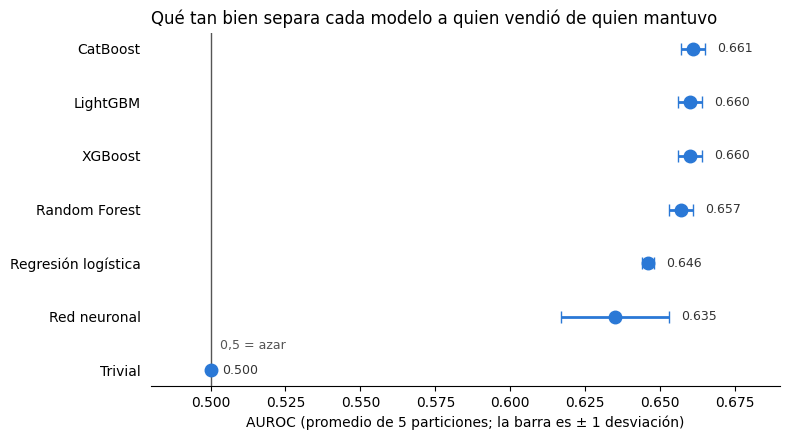

In [52]:
orden = view.sort_values("AUROC").index

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(view.loc[orden, "AUROC"], range(len(orden)), xerr=view.loc[orden, "±"],
            fmt="o", color=BLUE, markersize=9, capsize=4, linewidth=2)
for y, modelo in enumerate(orden):
    ax.text(view.loc[modelo, "AUROC"] + view.loc[modelo, "±"] + 0.004, y,
            f"{view.loc[modelo, 'AUROC']:.3f}", va="center", fontsize=9, color="#333333")
ax.axvline(0.5, color=GRAY, linewidth=1)
ax.text(0.503, 0.4, "0,5 = azar", color=GRAY, fontsize=9)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(0.48, 0.69)
ax.set_xlabel("AUROC (promedio de 5 particiones; la barra es ± 1 desviación)")
ax.set_title("Qué tan bien separa cada modelo a quien vendió de quien mantuvo", loc="left")
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout()
plt.show()

## Etapa 6. La regla del ganador

Del protocolo: gana el de mayor AUROC, **salvo** que un modelo más simple quede
a menos de una desviación estándar del mejor; en ese caso gana el más simple.
El orden de `MODELS` define qué es más simple.

La regla existe para no premiar diferencias que son ruido: si dos modelos están
dentro del margen de variación entre particiones, no hay evidencia de que uno
sea mejor, y entonces se prefiere el más simple de explicar y de mantener.

In [53]:
mejor = benchmark.loc[benchmark["auroc"].idxmax()]
corte = mejor["auroc"] - mejor["auroc_sd"]
elegibles = benchmark[benchmark["auroc"] >= corte]
ganador = train.choose_winner(benchmark)

print(f"Mejor AUROC:  {MODEL_NAMES[mejor['model']]} ({mejor['auroc']:.4f} ± {mejor['auroc_sd']:.4f})")
print(f"Entran los modelos con AUROC ≥ {corte:.4f}")
print(f"Elegibles:    {', '.join(MODEL_NAMES[m] for m in elegibles['model'])}")
print(f"Ganador:      {MODEL_NAMES[ganador]}  (el más simple de los elegibles)")

Mejor AUROC:  CatBoost (0.6613 ± 0.0039)
Entran los modelos con AUROC ≥ 0.6573
Elegibles:    XGBoost, LightGBM, CatBoost
Ganador:      XGBoost  (el más simple de los elegibles)


## Etapa 7. Los 32 experimentos

Antes de cerrar la elección, `bolsalab/modeling/experiments.py` prueba cuatro
modelos (XGBoost, LightGBM, CatBoost y la red neuronal) con dos rejillas de
ajustes y cuatro variantes de las variables, con las mismas reglas y la misma
partición. Para reemplazar al ganador, un experimento tenía que superarlo por
**más de una desviación**; esa regla quedó escrita antes de correrlos.

Aquí solo se leen los resultados. El detalle está en el notebook
*Comparación de modelos* y en `docs/experimentos.md`.

In [54]:
from bolsalab.modeling.experiments import EXPERIMENTS_FILE

experiments = pd.read_csv(EXPERIMENTS_FILE)
referencia = benchmark.set_index("model").loc[ganador]
umbral = referencia["auroc"] + referencia["auroc_sd"]
mejor_exp = experiments.loc[experiments["auroc"].idxmax()]

print(f"{len(experiments)} experimentos · AUROC entre {experiments['auroc'].min():.4f} y {experiments['auroc'].max():.4f}")
print(f"Para reemplazar a {MODEL_NAMES[ganador]} había que pasar de {umbral:.4f}")
print(f"El mejor fue {mejor_exp['experiment']} con {mejor_exp['auroc']:.4f}")
print("¿Alguno lo reemplaza?", "Sí" if (experiments["auroc"] > umbral).any() else "No")

32 experimentos · AUROC entre 0.6302 y 0.6613
Para reemplazar a XGBoost había que pasar de 0.6636
El mejor fue catboost|base|protocolo con 0.6613
¿Alguno lo reemplaza? No


## Etapa 8. Entrenar al ganador: antes y después del GridSearch

`fit_winner` lee `reports/benchmark.csv`, aplica la regla, y entrena a ese
modelo sobre **todo** el 80 % de entrenamiento, buscando sus hiperparámetros
con 3 particiones internas. El resultado es el modelo que se exporta.

Ya no hay particiones externas: aquí no se mide, se entrena el definitivo.

In [55]:
inicio = time.perf_counter()
nombre_ganador, search = train.fit_winner(X_train, y_train)
model = search.best_estimator_

print(f"Ganador: {MODEL_NAMES[nombre_ganador]}")
print(f"Hiperparámetros elegidos: {search.best_params_}")
print(f"AUROC en las 3 particiones internas: {search.best_score_:.4f}")
print(f"Tardó {time.perf_counter() - inicio:.0f} s")

Ganador: XGBoost
Hiperparámetros elegidos: {'model__learning_rate': 0.03, 'model__max_depth': 3}
AUROC en las 3 particiones internas: 0.6596
Tardó 6 s


In [56]:
# Todas las combinaciones que probó la búsqueda, de mejor a peor.
resultados = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
resultados.sort_values("mean_test_score", ascending=False).round(4).reset_index(drop=True)

,params,mean_test_score,std_test_score
0,"{'model__learning_rate': 0.03, 'model__max_dep...",0.6596,0.0030
1,"{'model__learning_rate': 0.1, 'model__max_dept...",0.6562,0.0023
2,"{'model__learning_rate': 0.03, 'model__max_dep...",0.6552,0.0016
3,"{'model__learning_rate': 0.1, 'model__max_dept...",0.6433,0.0011


### Antes y después del GridSearch

Hasta aquí vimos *qué* eligió la búsqueda. Esta parte mide **cuánto sirvió**:
compara el mismo modelo con sus valores por defecto contra el que salió del
GridSearch.

Las dos versiones se miden igual, con las mismas 5 particiones del
entrenamiento, y nunca con el 20 % de prueba. Lo importante es pedir también el
puntaje *sobre los datos con los que entrenó* (`return_train_score=True`): la
distancia entre ese puntaje y el de validación es el sobreajuste, y es lo que
el ajuste de hiperparámetros tiene que cerrar.

In [57]:
modelo_antes = clone(train.MODELS[nombre_ganador][0])  # sin ajustar
modelo_despues = model                                  # el del GridSearch

# XGBoost guarda como None los parámetros que no se fijaron: usa su valor
# interno por defecto (eta = 0,3 y max_depth = 6).
claves = [k.replace("model__", "") for k in train.MODELS[nombre_ganador][1]]
por_defecto = {"learning_rate": 0.3, "max_depth": 6}
valores_antes = modelo_antes.named_steps["model"].get_params()
valores_despues = modelo_despues.named_steps["model"].get_params()

pd.DataFrame(
    {
        "Antes (por defecto)": [
            valores_antes[k] if valores_antes[k] is not None else por_defecto.get(k, "por defecto")
            for k in claves
        ],
        "Después (GridSearch)": [valores_despues[k] for k in claves],
    },
    index=claves,
)

,Antes (por defecto),Después (GridSearch)
learning_rate,0.3,0.03
max_depth,6.0,3.00


In [58]:
particiones = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

comparacion = {}
for etiqueta, modelo in [("Antes", modelo_antes), ("Después", modelo_despues)]:
    s = cross_validate(clone(modelo), X_train, y_train, cv=particiones,
                       scoring=train.SCORERS, return_train_score=True, n_jobs=-1)
    comparacion[etiqueta] = {
        "AUROC entrenamiento": s["train_auroc"].mean(),
        "AUROC validación": s["test_auroc"].mean(),
        "±": s["test_auroc"].std(),
        "AUPRC validación": s["test_auprc"].mean(),
        "Brier validación": s["test_brier"].mean(),
        "Pendiente de calibración": s["test_calibration_slope"].mean(),
    }

comparacion = pd.DataFrame(comparacion).T
comparacion["Brecha (sobreajuste)"] = (
    comparacion["AUROC entrenamiento"] - comparacion["AUROC validación"])
comparacion.round(4)

,AUROC entrenamiento,AUROC validación,±,AUPRC validación,Brier validación,Pendiente de calibración,Brecha (sobreajuste)
Antes,0.9109,0.6083,0.0066,0.2855,0.1640,0.3400,0.3026
Después,0.6770,0.6601,0.0035,0.3307,0.1503,1.0556,0.0169


#### Gráfica 1: la brecha de sobreajuste

La barra de entrenamiento mide qué tan bien le va al modelo con las personas
que ya vio; la de validación, con personas nuevas. Un modelo útil tiene las dos
parecidas. Cuando la de entrenamiento se dispara y la de validación se queda
atrás, el modelo memorizó en lugar de aprender.

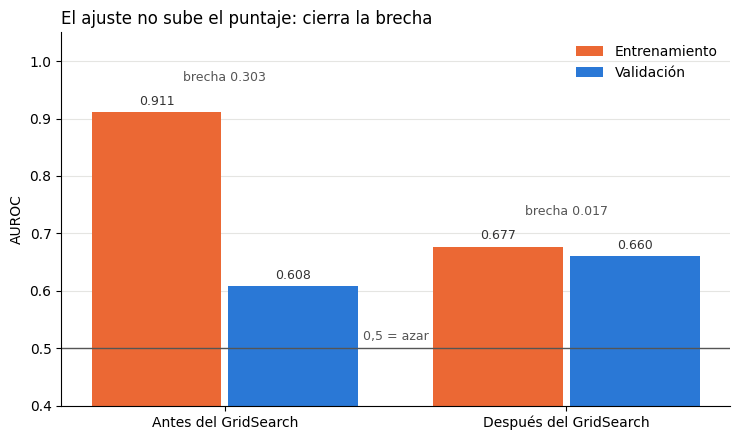

In [59]:
etiquetas = list(comparacion.index)
x = np.arange(len(etiquetas))
ancho = 0.38

fig, ax = plt.subplots(figsize=(7.5, 4.5))
barras = [
    ("Entrenamiento", comparacion["AUROC entrenamiento"], -ancho / 2 - 0.01, ORANGE),
    ("Validación", comparacion["AUROC validación"], ancho / 2 + 0.01, BLUE),
]
for nombre, valores, desplazamiento, color in barras:
    b = ax.bar(x + desplazamiento, valores, ancho, label=nombre, color=color)
    ax.bar_label(b, fmt="%.3f", padding=3, fontsize=9, color="#333333")

for i, etiqueta in enumerate(etiquetas):
    brecha = comparacion.loc[etiqueta, "Brecha (sobreajuste)"]
    ax.annotate(f"brecha {brecha:.3f}", (i, comparacion.loc[etiqueta, "AUROC entrenamiento"] + 0.055),
                ha="center", fontsize=9, color=GRAY)

ax.axhline(0.5, color=GRAY, linewidth=1)
ax.text((len(etiquetas) - 1) / 2, 0.515, "0,5 = azar", color=GRAY, fontsize=9, ha="center")
ax.set_xticks(x, [f"{e} del GridSearch" for e in etiquetas])
ax.set_ylim(0.4, 1.05)
ax.set_ylabel("AUROC")
ax.set_title("El ajuste no sube el puntaje: cierra la brecha", loc="left")
ax.legend(frameon=False, loc="upper right")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Gráfica 2: el mapa de la búsqueda

Cada celda es una combinación que el GridSearch probó, con su AUROC promedio en
las 3 particiones internas. Sirve para ver si la búsqueda encontró una
diferencia real o si todas las combinaciones daban casi lo mismo, y si el mejor
valor quedó en el borde de la rejilla (señal de que conviene ampliarla).

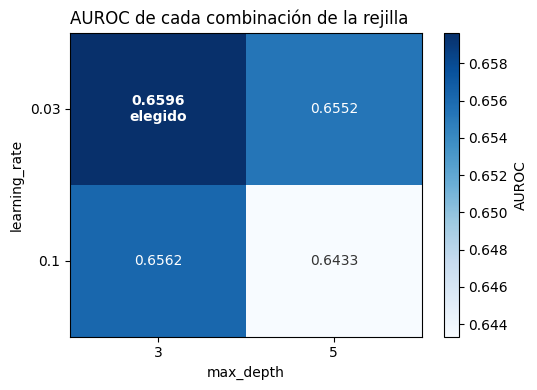

Mejor 0.6596 · peor 0.6433 · rango 0.0163


In [60]:
resultados_rejilla = pd.DataFrame(search.cv_results_)
nombres = [c for c in resultados_rejilla.columns if c.startswith("param_")]
fila, columna = nombres[0], nombres[1]

mapa = resultados_rejilla.pivot_table(index=fila, columns=columna, values="mean_test_score")

fig, ax = plt.subplots(figsize=(5.5, 4))
mapa_color = plt.get_cmap("Blues")
escala = plt.Normalize(mapa.values.min(), mapa.values.max())
im = ax.imshow(mapa.values, cmap=mapa_color, norm=escala, aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        valor = mapa.values[i, j]
        # Texto blanco solo donde el azul es oscuro, midiendo la luminancia
        # real del color de la celda en vez de un umbral fijo.
        r, g, b, _ = mapa_color(escala(valor))
        oscuro = 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45
        elegido = valor == mapa.values.max()
        ax.text(j, i, f"{valor:.4f}" + ("\nelegido" if elegido else ""),
                ha="center", va="center", fontsize=10,
                color="white" if oscuro else "#333333",
                fontweight="bold" if elegido else "normal")
ax.set_xticks(range(mapa.shape[1]), mapa.columns)
ax.set_yticks(range(mapa.shape[0]), mapa.index)
ax.set_xlabel(columna.replace("param_model__", ""))
ax.set_ylabel(fila.replace("param_model__", ""))
ax.set_title("AUROC de cada combinación de la rejilla", loc="left")
fig.colorbar(im, ax=ax, label="AUROC")
plt.tight_layout()
plt.show()

print(f"Mejor {mapa.values.max():.4f} · peor {mapa.values.min():.4f} · "
      f"rango {mapa.values.max() - mapa.values.min():.4f}")

#### Gráficas 3 y 4: curva ROC y curva de calibración

Las dos se construyen con las probabilidades de validación cruzada, así que
cada persona recibe la probabilidad de un modelo que no la vio.

- **La curva ROC** muestra cómo separa a quien vendió de quien mantuvo, para
  todos los umbrales a la vez. Entre más se despegue de la diagonal, mejor.
- **La curva de calibración** agrupa a las personas en diez grupos por su
  probabilidad y compara lo que el modelo predijo con lo que de verdad pasó.
  Sobre la diagonal, las probabilidades se pueden leer como porcentajes de
  verdad; lejos de la diagonal, solo sirven para ordenar.

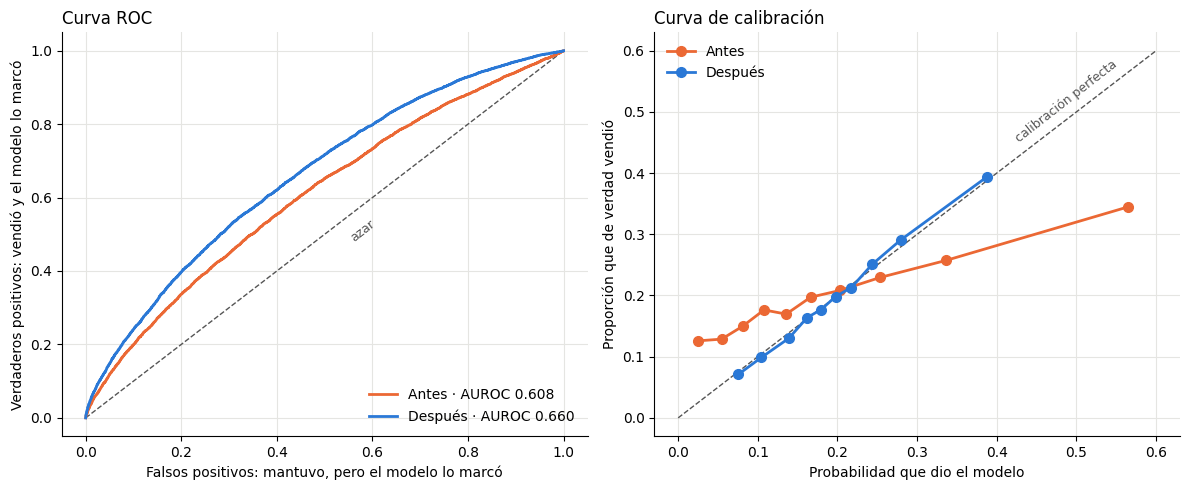

In [61]:
probabilidades = {}
for etiqueta, modelo in [("Antes", modelo_antes), ("Después", modelo_despues)]:
    probabilidades[etiqueta] = cross_val_predict(
        clone(modelo), X_train, y_train, cv=particiones, method="predict_proba", n_jobs=-1)[:, 1]

COLORES = {"Antes": ORANGE, "Después": BLUE}

fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 5))

izq.plot([0, 1], [0, 1], color=GRAY, linewidth=1, linestyle="--")
izq.text(0.55, 0.48, "azar", color=GRAY, fontsize=9, rotation=38)
for etiqueta, p in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_train, p)
    auc = roc_auc_score(y_train, p)
    izq.plot(fpr, tpr, color=COLORES[etiqueta], linewidth=2,
             label=f"{etiqueta} · AUROC {auc:.3f}")
izq.set_xlabel("Falsos positivos: mantuvo, pero el modelo lo marcó")
izq.set_ylabel("Verdaderos positivos: vendió y el modelo lo marcó")
izq.set_title("Curva ROC", loc="left")
izq.legend(frameon=False, loc="lower right")

der.plot([0, 0.6], [0, 0.6], color=GRAY, linewidth=1, linestyle="--")
der.text(0.42, 0.45, "calibración perfecta", color=GRAY, fontsize=9, rotation=38)
for etiqueta, p in probabilidades.items():
    observado, predicho = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    der.plot(predicho, observado, "o-", color=COLORES[etiqueta], linewidth=2,
             markersize=7, label=etiqueta)
der.set_xlabel("Probabilidad que dio el modelo")
der.set_ylabel("Proporción que de verdad vendió")
der.set_title("Curva de calibración", loc="left")
der.legend(frameon=False, loc="upper left")

for ax in (izq, der):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.grid(color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Qué se puede analizar aquí

| Herramienta | Qué pregunta responde |
|---|---|
| `return_train_score` y la brecha | ¿El modelo memorizó o aprendió? |
| `cv_results_` y el mapa de la rejilla | ¿La búsqueda encontró algo o todo daba igual? ¿Hay que ampliar la rejilla? |
| Curva ROC | ¿Ordena mejor a las personas después de ajustar? |
| Curva de calibración | ¿Las probabilidades se pueden leer como porcentajes? |
| Rango de las probabilidades | ¿El modelo da probabilidades extremas que no puede sostener? |

Lo que no se puede analizar aquí: nada de esto se mide en el 20 % de prueba. Es
todo validación cruzada sobre el entrenamiento, que es justo lo que permite
mirar cuantas veces haga falta.

## Etapa 9. Los cortes de la app

La app no muestra una probabilidad, muestra tres categorías. Los cortes son los
percentiles 33,3 y 66,7 de las probabilidades del entrenamiento (protocolo,
sección 8).

Esas probabilidades se calculan con validación cruzada de 5 particiones, no con
el modelo ya entrenado: así cada persona recibe la probabilidad de un modelo
que no la vio, y los cortes no quedan corridos por el sobreajuste. Es
exactamente lo que hace `train.category_cutoffs`, escrito aquí paso a paso para
poder graficar la distribución.

In [62]:
folds = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
p_train = cross_val_predict(clone(model), X_train, y_train, cv=folds, method="predict_proba")[:, 1]
cortes = [float(q) for q in np.quantile(p_train, [1 / 3, 2 / 3])]

print(f"Probabilidades entre {p_train.min():.3f} y {p_train.max():.3f} (media {p_train.mean():.3f})")
print(f"Cortes: bajo < {cortes[0]:.3f} ≤ medio < {cortes[1]:.3f} ≤ alto")

Probabilidades entre 0.053 y 0.847 (media 0.199)
Cortes: bajo < 0.159 ≤ medio < 0.221 ≤ alto


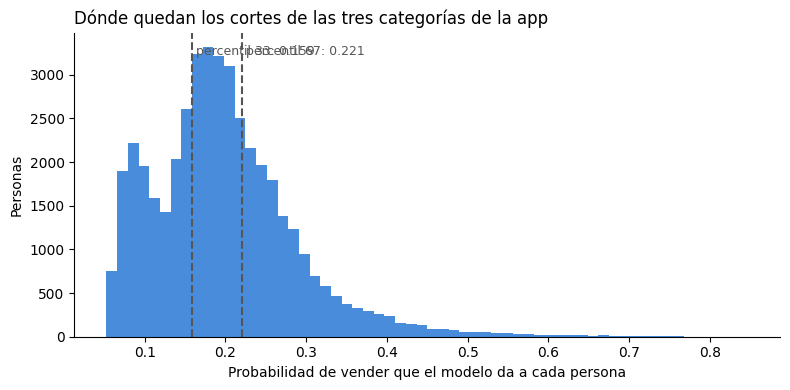

In [63]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(p_train, bins=60, color=BLUE, alpha=0.85)
for corte, etiqueta in zip(cortes, ["percentil 33", "percentil 67"]):
    ax.axvline(corte, color=GRAY, linewidth=1.5, linestyle="--")
    ax.text(corte, ax.get_ylim()[1] * 0.96, f" {etiqueta}: {corte:.3f}",
            color=GRAY, fontsize=9, va="top")
ax.set_xlabel("Probabilidad de vender que el modelo da a cada persona")
ax.set_ylabel("Personas")
ax.set_title("Dónde quedan los cortes de las tres categorías de la app", loc="left")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

El resto de lo que la app necesita del entrenamiento: con qué valor rellenar las
dos preguntas que todavía no hace, cómo traducir los cinco niveles de ingreso y
activos a los tramos japoneses, y el rango de edad admitido.

In [64]:
referencia_app = train.app_reference(X_train)
{k: v for k, v in referencia_app.items() if k != "features"}

{'not_asked': {'risk_aversion': 0.5, 'short_term_view': 2.0},
 'income_level_to_bracket': {1: 3, 2: 4, 3: 5, 4: 6, 5: 8},
 'assets_level_to_bracket': {1: 1, 2: 3, 3: 5, 4: 7, 5: 9},
 'age_range': [18, 93]}

## Etapa 10. Desempeño por grupos

Antes de dar el modelo por bueno hay que revisar si funciona peor para algún
grupo. `groups.py` parte el entrenamiento por sexo, edad e ingreso y mide
AUROC y calibración en cada uno, con las mismas probabilidades de validación
cruzada de la etapa 9.

Un AUROC parecido entre grupos dice que el modelo ordena igual de bien en
todos; una calibración distinta dice que las probabilidades están corridas para
alguno.

In [65]:
grupos = performance_by_group(model, X_train, y_train)
grupos = grupos.rename(columns={
    "grupo": "Corte", "valor": "Grupo", "personas": "Personas",
    "vendio": "Vendió", "prediccion_media": "Predicción media",
    "auroc": "AUROC", "calibration_intercept": "Intercepto",
    "calibration_slope": "Pendiente",
})
grupos.set_index(["Corte", "Grupo"]).round(3)

Personas  Vendió  Predicción media  AUROC  Intercepto  \
Corte   Grupo                                                                   
Sexo    Hombres            29348   0.236             0.235  0.623       0.077   
        Mujeres            14415   0.122             0.125  0.643       0.076   
Edad    18 a 39            13449   0.183             0.182  0.693       0.184   
        40 a 59            22635   0.189             0.190  0.646       0.044   
        60 o más            7679   0.256             0.253  0.588      -0.140   
Ingreso Tramos 1 a 4       18045   0.222             0.220  0.660       0.034   
        Tramos 5 a 7       20103   0.179             0.182  0.653       0.083   
        Tramos 8 o más      5615   0.195             0.190  0.652       0.225   

                        Pendiente  
Corte   Grupo                      
Sexo    Hombres             1.060  
        Mujeres             1.056  
Edad    18 a 39             1.127  
        40 a 59             1.038  
        60 o más            0.854  
Ingreso Tramos 1 a 4        1.017  
        Tramos 5 a 7        1.074  
        Tramos 8 o más      1.140

## Etapa 11. La prueba final

Aquí se usa por primera y única vez el 20 % apartado en la etapa 2.

> **El protocolo permite mirarlo una sola vez.** Cada vez que se mira y después
> se cambia algo del modelo, el número deja de ser una estimación honesta del
> desempeño y pasa a ser el mejor de varios intentos. Por eso el interruptor
> está en `False` y lo normal es correr
> `uv run python -m bolsalab.modeling.train --final` una vez, desde la terminal.

El resultado oficial ya medido está guardado en
`models/crash_reaction_v1.json`, así que se puede consultar sin volver a medir.

In [66]:
metadata_file = MODELS_DIR / "crash_reaction_v1.json"
if metadata_file.exists():
    metadata = json.loads(metadata_file.read_text(encoding="utf-8"))
    print(f"Artefacto entrenado el {metadata['trained_on']} · ganador: {metadata['winner']}")
    print("Métricas de prueba guardadas:", metadata["test"] or "todavía ninguna (exportado con --prototype)")
else:
    print("Todavía no hay artefacto exportado en models/.")

Artefacto entrenado el 2026-10-23 · ganador: xgboost
Métricas de prueba guardadas: todavía ninguna (exportado con --prototype)


In [67]:
if MEDIR_EN_PRUEBA:
    metricas = train.evaluate_on_test(model, X_test, y_test)
    for nombre, valor in metricas.items():
        print(f"{nombre:24} {valor}")
else:
    print("MEDIR_EN_PRUEBA = False → no se tocó el 20 % de prueba.")
    print("Cámbialo a True solo si de verdad corresponde medir ahora.")

MEDIR_EN_PRUEBA = False → no se tocó el 20 % de prueba.
Cámbialo a True solo si de verdad corresponde medir ahora.


## Etapa 12. Exportar el artefacto

`export_model` guarda dos archivos en `models/`: el `Pipeline` entrenado en
`.joblib` y, en `.json`, las métricas, los cortes de la etapa 9, la referencia
de la app y las versiones con las que se entrenó. Es lo único que la API y la
app necesitan cargar.

Lo normal es que esto lo haga el script (`--prototype` o `--final`), no el
notebook; la celda está para poder ver qué queda escrito.

In [ ]:
if EXPORTAR_MODELO:
    metricas = train.evaluate_on_test(model, X_test, y_test) if MEDIR_EN_PRUEBA else None
    train.export_model(
        model,
        {"winner": nombre_ganador, "params": search.best_params_, "test": metricas},
        X_train,
        y_train,
    )
    print(f"Guardado en {MODELS_DIR}")
else:
    print("EXPORTAR_MODELO = False → no se sobrescribió nada en models/.")

## Resumen: cada etapa y su comando

| Etapas | Comando equivalente |
|---|---|
| 1 | `uv run python -m bolsalab.features` |
| 2 a 6 | `uv run python -m bolsalab.modeling.train` |
| 7 | `uv run python -m bolsalab.modeling.experiments` |
| 8, 9, 12 | `uv run python -m bolsalab.modeling.train --prototype` |
| 8 a 12 | `uv run python -m bolsalab.modeling.train --final` |
| 10 | `uv run python -m bolsalab.modeling.groups` |

## Para seguir

- **Comparación de modelos:** el detalle de los 7 modelos y los 24 experimentos.
- **Explicación del modelo con SHAP:** qué variables pesan y hacia dónde empujan.
- **NFCS frente a Japón:** si el modelo se sostiene con datos de EE. UU.
- `docs/protocolo-evaluacion.md`: las reglas completas.